# Модуль 1. Данные, EDA и бейзлайн: УРС алюминия

**Кейс:** нейросетевая аппроксимация широкодиапазонного уравнения состояния (УРС) алюминия с учётом термодинамических ограничений.

Ноутбук выполняет этап 1 технического задания:

1. **1.1** загрузка 20 табличных областей и EDA;
2. **1.2** сечения $P$ и $E$ при 4 фиксированных $T$ и 4 фиксированных $\rho$;
3. **1.3** бейзлайн: билинейная интерполяция, её точность и скорость;
4. **1.4** сохранённые коэффициенты нормировки (`artifacts/models/normalization.json`).

Дополнительно проверяется физическая корректность самих данных: термодинамическая согласованность, устойчивость, шум, разрывы на границах областей.
Вся логика лежит в пакете `eos/` (модули `data`, `eda`, `physics`, `baseline`); ноутбук только вызывает её и показывает результаты.

Единицы: $\rho$ [г/см³], $T$ [K], $P$ [ГПа], $E$ [кДж/г]. Удобно, что ГПа/(г/см³) = кДж/г, а $\sqrt{\text{кДж/г}}$ = км/с, поэтому $P/\rho$ и $E$ сравнимы напрямую, а скорость звука сразу получается в км/с.

In [1]:
import sys, json, time, types
from pathlib import Path

# eos.physics импортирует torch, но модулю 1 он не нужен (используется только numpy-часть).
# На Windows ядро Jupyter загружает zmq раньше torch, и тогда c10.dll не загружается (WinError 1114),
# поэтому при такой ошибке подставляется пустой модуль.
try:
    import torch
except OSError as err:
    print("torch недоступен в ядре Jupyter, используется заглушка:", type(err).__name__)
    sys.modules["torch"] = types.ModuleType("torch")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from eos.config import FIG_DIR, NORM_FILE, REPORT_DIR
from eos.data import load_regions, load_dataset, Normalizer, RHO_EDGES, T_EDGES
from eos import eda
from eos.physics import fd_thermo_residual
from eos.baseline import BilinearEOS, benchmark
from eos.metrics import summarize, rel_errors

%matplotlib inline
OUT = FIG_DIR / "module1"          # рисунки модуля 1
TAB = REPORT_DIR / "module1"       # таблицы модуля 1
OUT.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
fmt = lambda df: df.style.format(precision=4, thousands=" ")
print("Корень проекта:", ROOT)

torch недоступен в ядре Jupyter, используется заглушка: OSError
Корень проекта: C:\Users\Наталья\Desktop\ROSATOM\prototype


## 1.1. Загрузка данных

Каждый файл `OblNN.txt` содержит прямоугольную сетка $(\rho, T)$ с колонками `rho T P e`; тип сетки (lin/log по каждой оси) читается из заголовка.
Области: 4 диапазона плотности × 5 диапазонов температуры, нумерация `Obl = 5·i_ρ + i_T + 1`.

Разбиение на выборки (внутри каждой области, по индексам узлов $i$ по $\rho$ и $j$ по $T$):
* **test**: узлы с нечётными $i$ и $j$ (≈25 %): это ровно центры ячеек прореженной сетки, поэтому test честен и для бейзлайна, и для нейросети;
* **train**: остальные узлы (≈75 %), из них случайные 5 % идут в **validation**;
* сетка бейзлайна: узлы с чётными $i$ и $j$ (≈25 %).

Сводный датасет кэшируется в `artifacts/cache/dataset.npz`.

In [2]:
t0 = time.perf_counter()
regions = load_regions()
t_read = time.perf_counter() - t0
ds = load_dataset()
print(f"Чтение 20 txt-файлов: {t_read:.1f} с; кэш dataset.npz: {len(ds['P']):,} точек".replace(",", " "))

rows = []
for k, r in enumerate(regions):
    m = ds["region"] == k
    rows.append({"область": r.name, "сетка": r.grid, "n_rho": len(r.rho), "n_T": len(r.T),
                 "точек": r.P.size, "rho_min": r.rho[0], "rho_max": r.rho[-1],
                 "T_min": r.T[0], "T_max": r.T[-1], "P_min": r.P.min(), "P_max": r.P.max(),
                 "E_min": r.E.min(), "E_max": r.E.max(),
                 "train": int(((ds["split"] == 0) & m).sum()), "val": int(((ds["split"] == 1) & m).sum()),
                 "test": int(((ds["split"] == 2) & m).sum())})
region_table = pd.DataFrame(rows).set_index("область")
region_table.to_csv(TAB / "regions_summary.csv", encoding="utf-8-sig")
region_table.style.format({c: "{:.4g}" for c in ["rho_min", "rho_max", "T_min", "T_max",
                                                  "P_min", "P_max", "E_min", "E_max"]})

Чтение 20 txt-файлов: 4.5 с; кэш dataset.npz: 1 130 053 точек


,сетка,n_rho,n_T,точек,rho_min,rho_max,T_min,T_max,P_min,P_max,E_min,E_max,train,val,test
область,,,,,,,,,,,,,,,
Obl01,"rho=log, T=log",158,158,24964,0.001,0.09713,0.1,95.72,0.0005154,1.536,-46.8,-38.93,17806,917,6241
Obl02,"rho=log, T=log",200,200,40000,0.001,0.09772,100,2949,0.4963,15.88,-46.66,-34.46,28488,1512,10000
Obl03,"rho=log, T=log",200,200,40000,0.001,0.09772,3000,2.966e+04,14.96,153.7,-37.53,87.14,28480,1520,10000
Obl04,"rho=log, T=lin",274,274,75076,0.001,0.09833,3e+04,9.974e+04,149.7,521.7,62.3,448.6,53551,2756,18769
Obl05,"rho=log, T=log",200,200,40000,0.001,0.09772,1e+05,1e+07,499.1,6.019e+04,404.6,1.679e+05,28516,1484,10000
Obl06,"rho=log, T=log",158,158,24964,0.1,1.475,0.1,95.72,1.11,69.84,-38.86,-2.077,17799,924,6241
Obl07,"rho=log, T=log",245,245,60025,0.1,1.484,100,2959,1.609,84.75,-38.76,0.9893,42842,2299,14884
Obl08,"rho=log, T=log",245,245,60025,0.1,1.484,3000,2.972e+04,16.18,244.5,-34.26,60.95,42958,2183,14884
Obl09,"rho=log, T=lin",274,274,75076,0.1,1.485,3e+04,9.974e+04,155.7,779.9,49.4,402.3,53513,2794,18769


In [3]:
P, E, split = ds["P"], ds["E"], ds["split"]
print(f"NaN/inf: P {(~np.isfinite(P)).sum()}, E {(~np.isfinite(E)).sum()}")
print(f"P: {P.min():.3e} .. {P.max():.3e} ГПа, все P > 0: {bool((P > 0).all())}, "
      f"диапазон {np.log10(P.max() / P.min()):.1f} порядков")
print(f"E: {E.min():.2f} .. {E.max():.3e} кДж/г, доля E < 0: {(E < 0).mean():.1%}")
print(f"rho: {ds['rho'].min():g} .. {ds['rho'].max():g} г/см³, T: {ds['T'].min():g} .. {ds['T'].max():g} K")
print("Выборки:", {n: int((split == s).sum()) for s, n in enumerate(("train", "val", "test"))},
      f"| сетка бейзлайна: {int(ds['coarse'].sum())}")

NaN/inf: P 0, E 0
P: 5.154e-04 .. 1.591e+09 ГПа, все P > 0: True, диапазон 12.5 порядков
E: -46.80 .. 1.679e+05 кДж/г, доля E < 0: 19.4%
rho: 0.001 .. 10000 г/см³, T: 0.1 .. 1e+07 K
Выборки: {'train': 805944, 'val': 42263, 'test': 281846} | сетка бейзлайна: 283183


### EDA: распределения, карты, сечения

Рисунки строит `eos.eda.run(ds)` (≈1 мин, сохраняет PNG в `artifacts/figures/` и `artifacts/reports/eda_summary.json`).
По умолчанию показываются уже построенные файлы; `REGENERATE = True` перестраивает их.

* `eda_distributions.png`: гистограммы $\log_{10}P$ и $\mathrm{sign}(E)\log_{10}(1+|E|)$, число точек по областям;
* `eda_maps.png`: карты $P$, $E$, относительной невязки термодинамической согласованности (конечные разности) и узлов, где в данных нарушается устойчивость;
* `eda_sections.png`: изотермы и изохоры $P$ и $E$.

eda_distributions.png


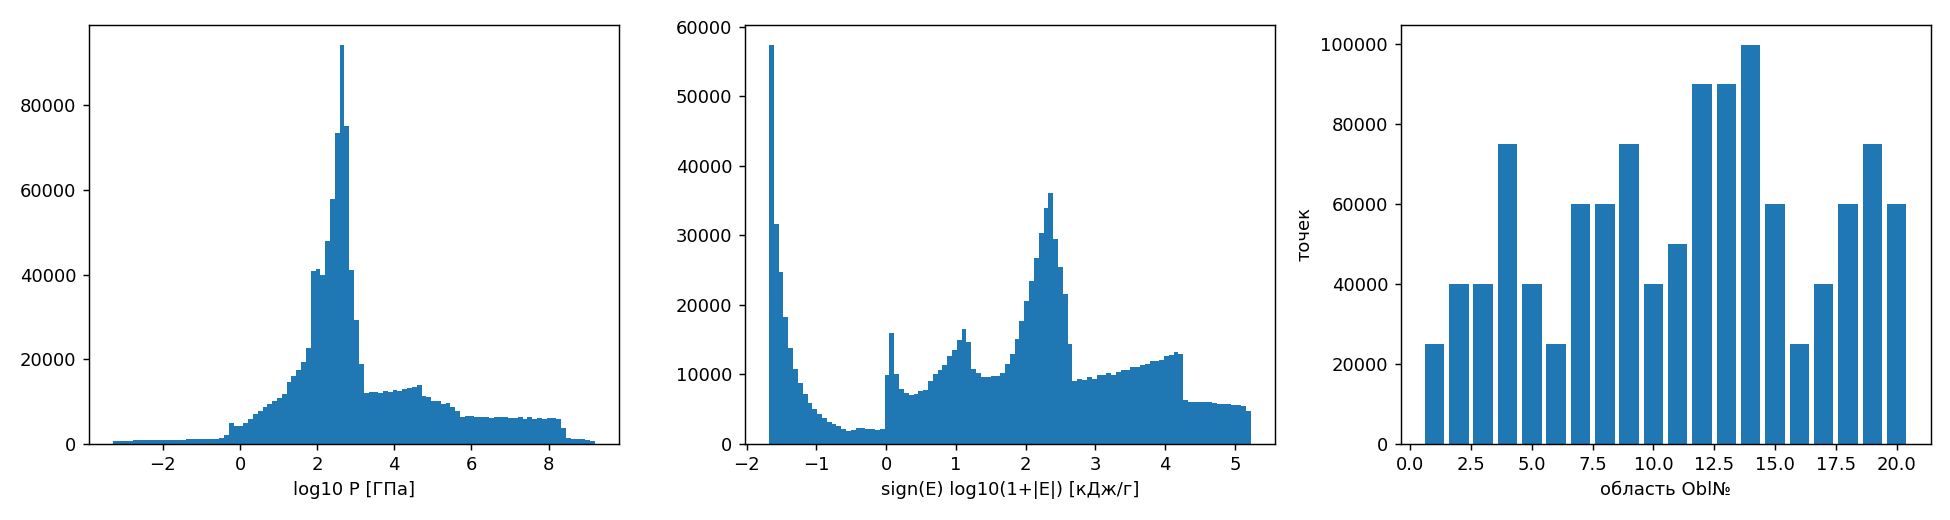

eda_maps.png


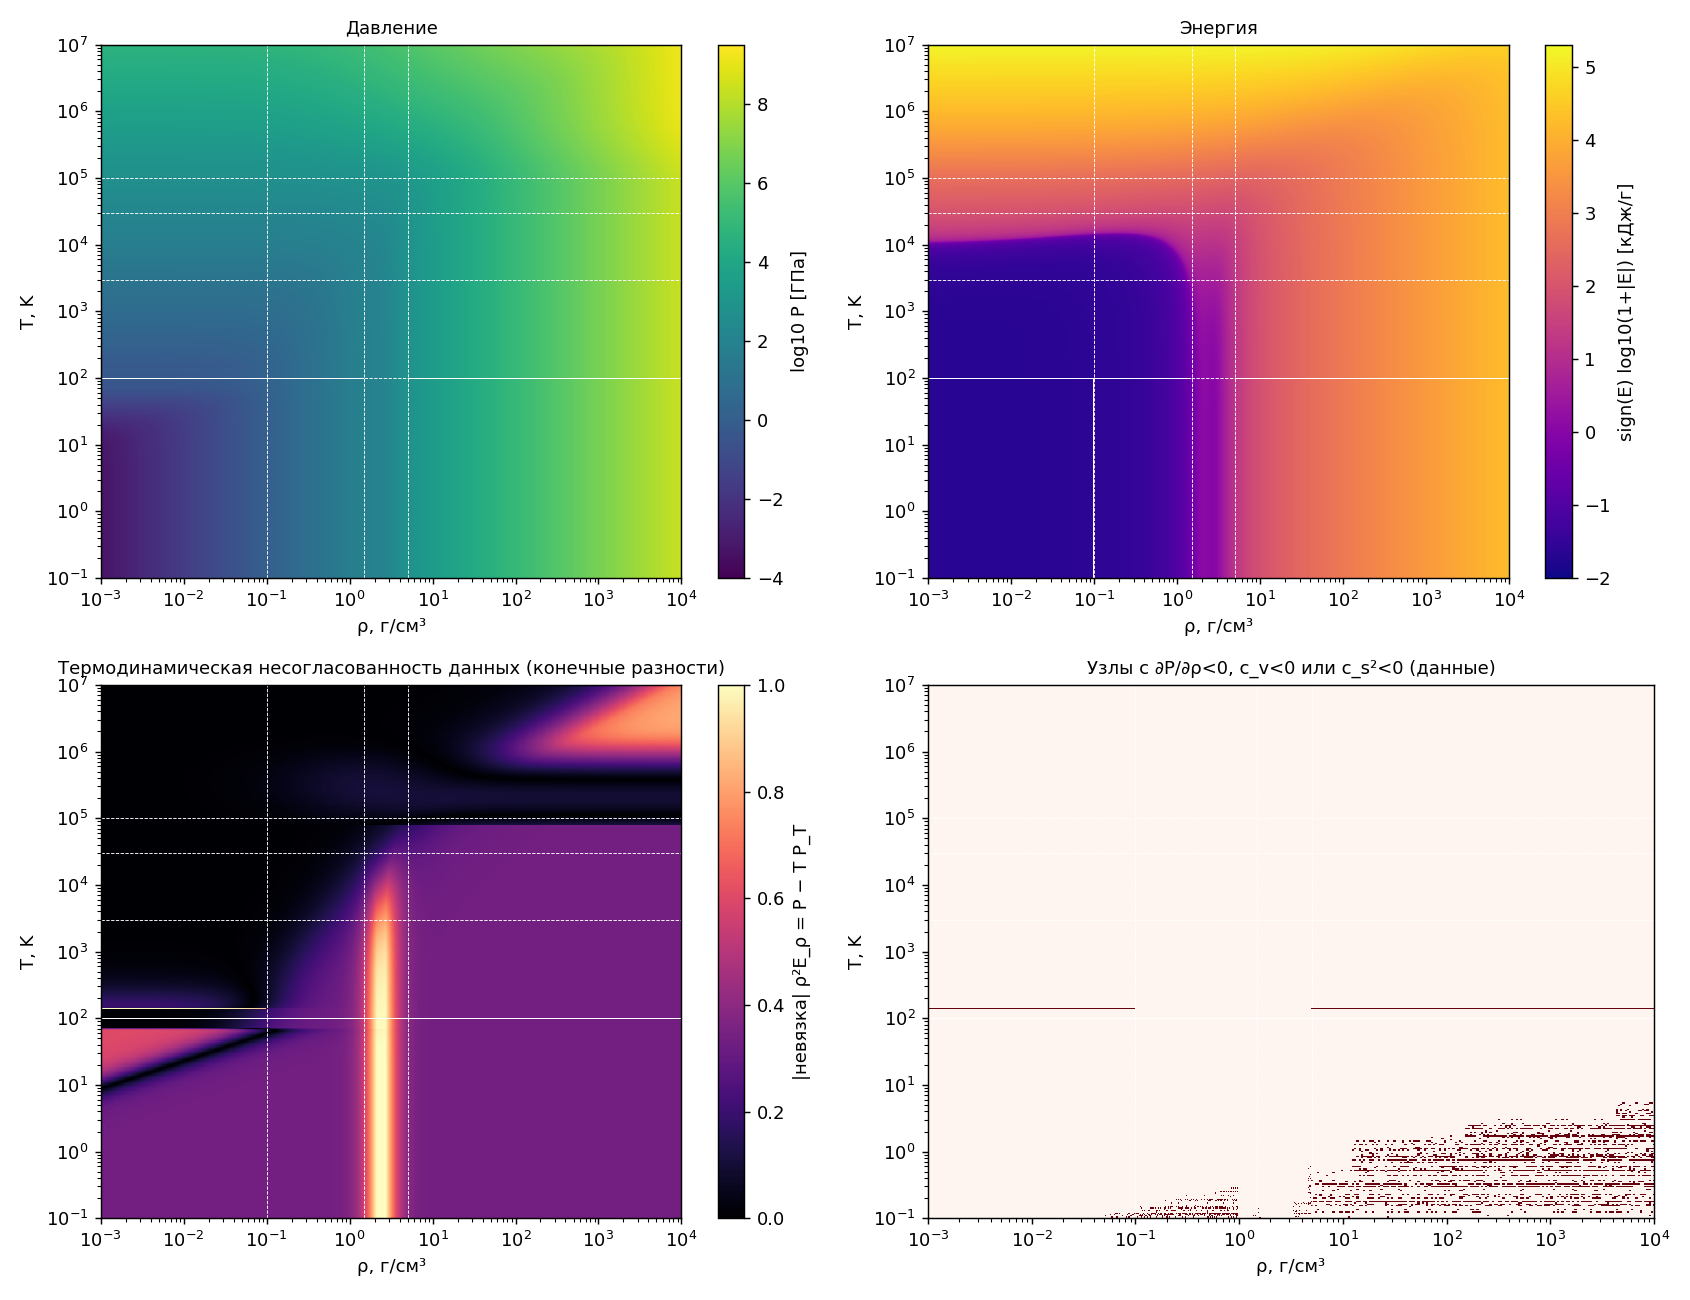

eda_sections.png


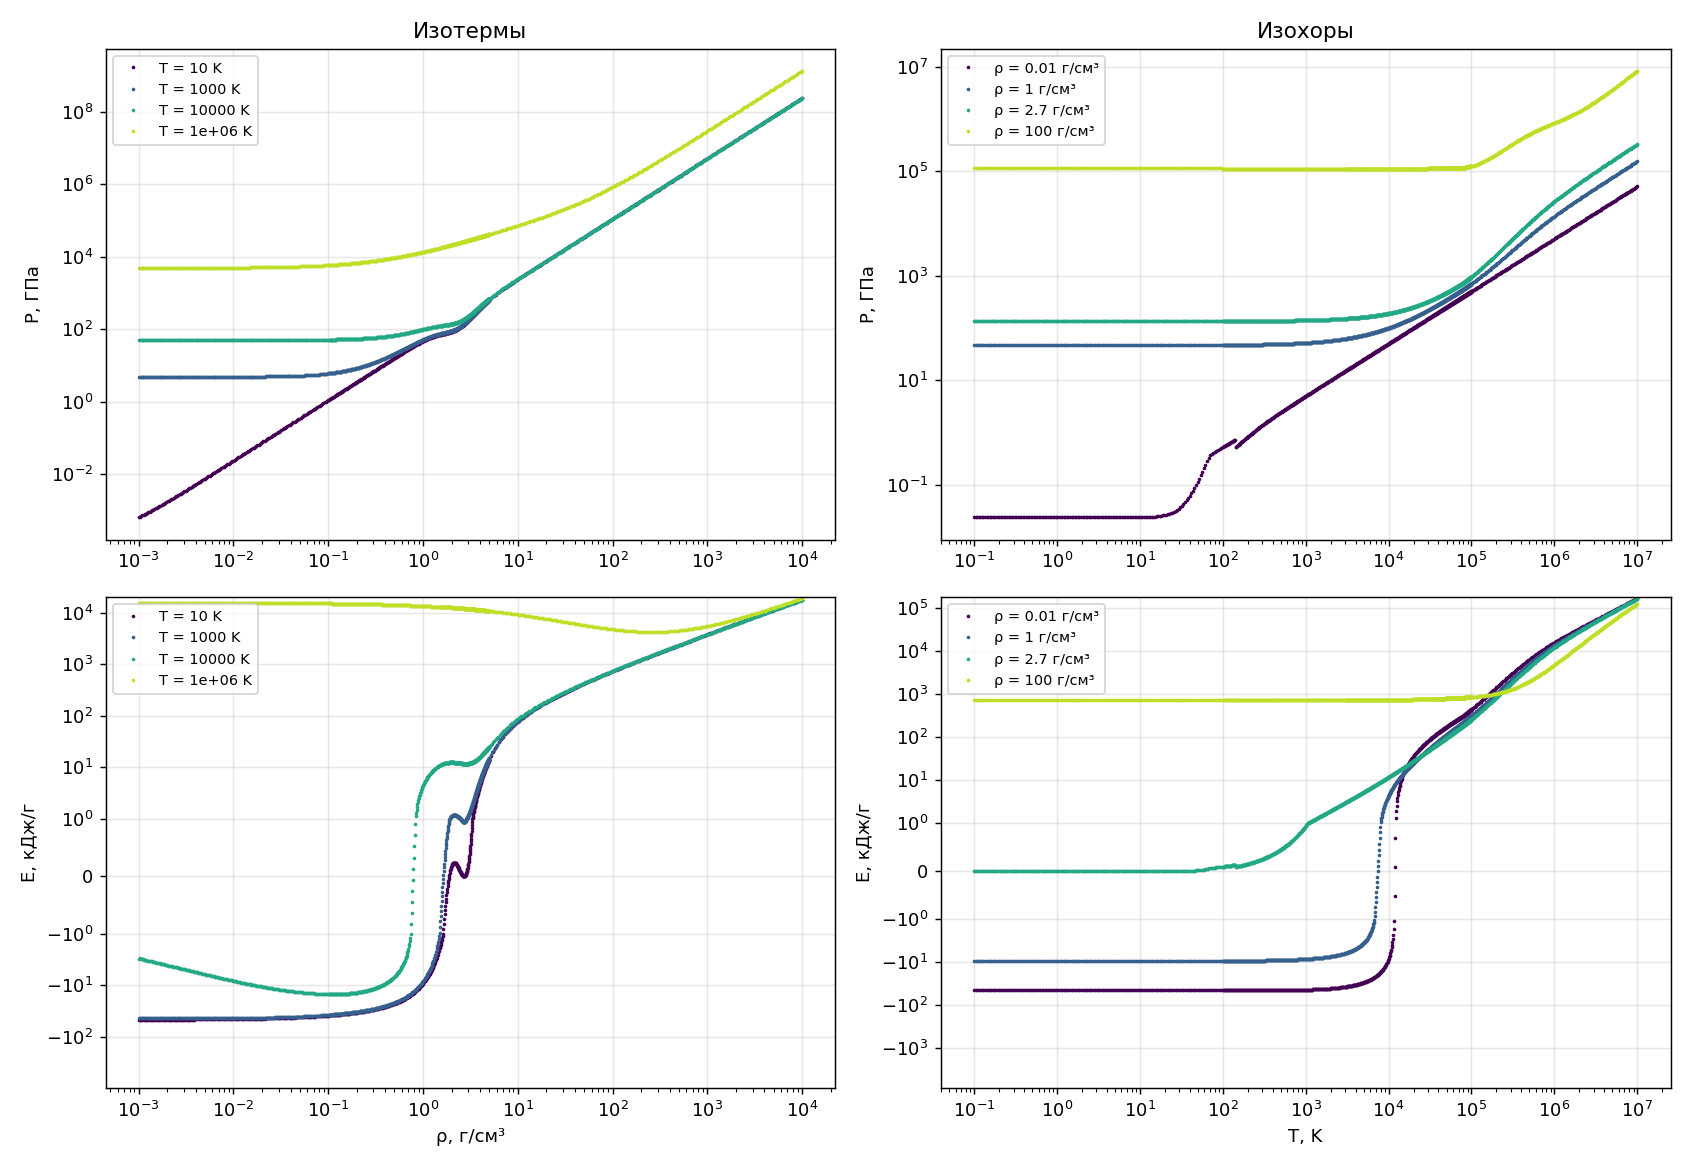

In [4]:
REGENERATE = False
if REGENERATE or not (FIG_DIR / "eda_maps.png").exists():
    eda.run(ds)
for name in ("eda_distributions.png", "eda_maps.png", "eda_sections.png"):
    print(name)
    display(Image(filename=str(FIG_DIR / name), width=1000))

In [5]:
with open(REPORT_DIR / "eda_summary.json", encoding="utf-8") as f:
    eda_summary = pd.DataFrame(json.load(f)).T
eda_cols = ["frac_dPdrho_neg", "frac_cv_neg", "thermo_residual_median", "P_second_diff_mean_ln"]
eda_summary[eda_cols].astype(float).style.format("{:.2e}")

,frac_dPdrho_neg,frac_cv_neg,thermo_residual_median,P_second_diff_mean_ln
Obl01,0.00e+00,6.57e-04,3.33e-01,8.26e-04
Obl02,0.00e+00,1.01e-02,1.67e-02,6.39e-05
Obl03,0.00e+00,0.00e+00,2.24e-04,6.60e-06
Obl04,0.00e+00,0.00e+00,9.69e-05,2.70e-06
Obl05,0.00e+00,0.00e+00,6.94e-04,1.51e-05
Obl06,0.00e+00,1.90e-02,3.33e-01,1.09e-04
Obl07,0.00e+00,8.23e-03,2.40e-01,7.19e-05
Obl08,0.00e+00,0.00e+00,4.57e-02,3.81e-05
Obl09,0.00e+00,0.00e+00,1.26e-02,9.14e-06
Obl10,0.00e+00,0.00e+00,2.05e-02,3.10e-05


## 1.2. Сечения $P$ и $E$ при фиксированных $T$ и $\rho$

Точки: табличные данные (во всех областях, куда попадает сечение), линии: бейзлайн (билинейная интерполяция по прореженной сетке).
Сечения: $T$ = 10, 10³, 10⁴, 10⁶ K и $\rho$ = 0.01, 1, 2.7 (нормальная плотность Al), 100 г/см³.

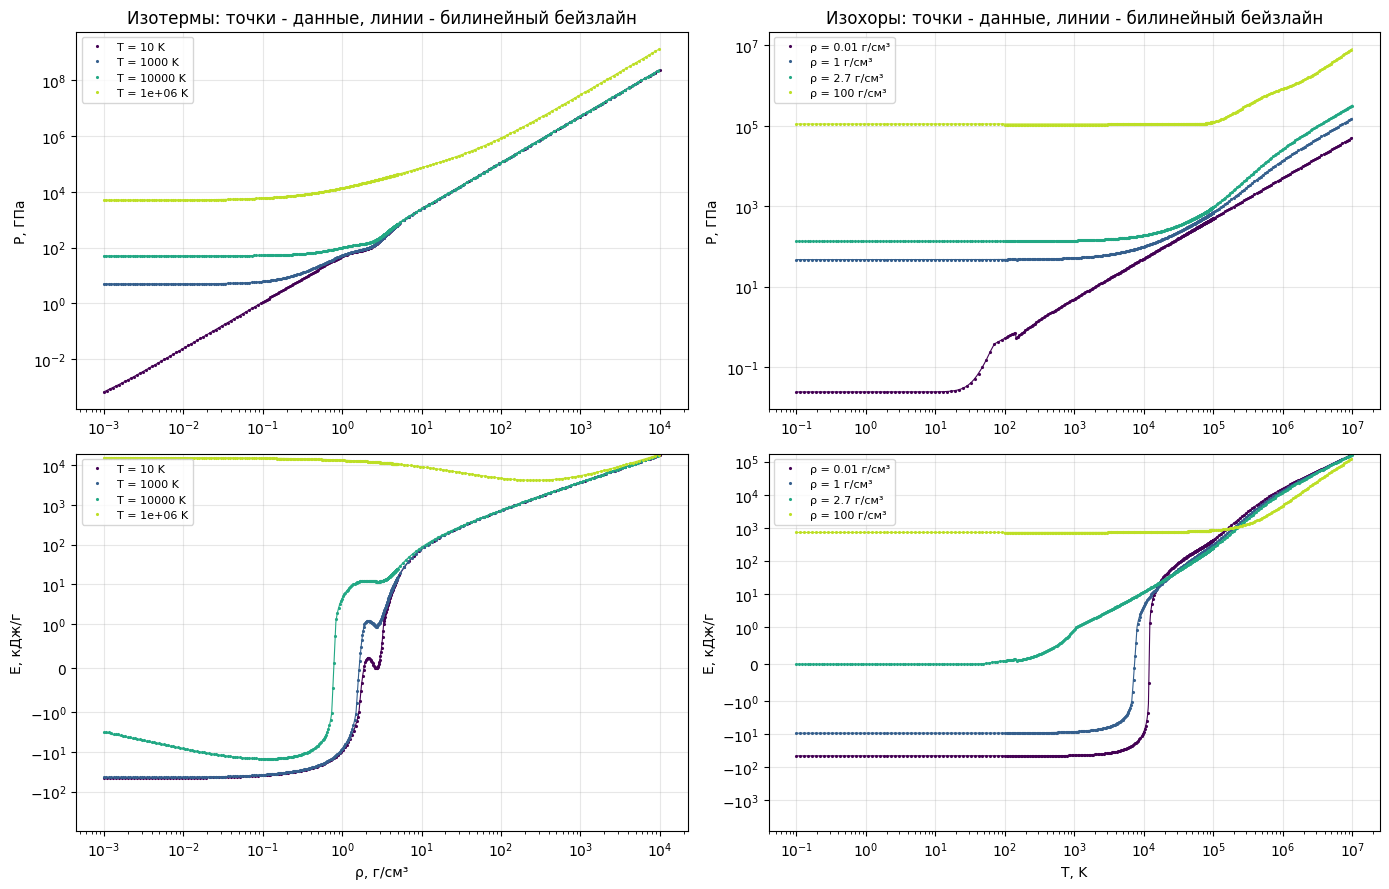

In [6]:
bl = BilinearEOS.from_dataset(ds, coarse=True)   # строится по узлам с чётными индексами

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = plt.cm.viridis(np.linspace(0, 0.9, 4))
for c, T0 in zip(colors, eda.T_CUTS):
    xx = np.geomspace(RHO_EDGES[0], RHO_EDGES[-1], 2000)
    Pb, Eb = bl.predict(xx, np.full_like(xx, T0))
    for ax, field, yb in ((axes[0, 0], "P", Pb), (axes[1, 0], "E", Eb)):
        x, y = eda.section_rho(regions, T0, field)
        ax.plot(x[::3], y[::3], ".", ms=2.5, color=c, label=f"T = {T0:g} K")
        ax.plot(xx, yb, "-", lw=0.8, color=c)
for c, r0 in zip(colors, eda.RHO_CUTS):
    xx = np.geomspace(T_EDGES[0], T_EDGES[-1], 2000)
    Pb, Eb = bl.predict(np.full_like(xx, r0), xx)
    for ax, field, yb in ((axes[0, 1], "P", Pb), (axes[1, 1], "E", Eb)):
        x, y = eda.section_T(regions, r0, field)
        ax.plot(x[::3], y[::3], ".", ms=2.5, color=c, label=f"ρ = {r0:g} г/см³")
        ax.plot(xx, yb, "-", lw=0.8, color=c)
for ax in axes.ravel():
    ax.set_xscale("log"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
for ax in axes[0]:
    ax.set_yscale("log"); ax.set_ylabel("P, ГПа")
for ax in axes[1]:
    ax.set_yscale("symlog", linthresh=1.0); ax.set_ylabel("E, кДж/г")
axes[1, 0].set_xlabel("ρ, г/см³"); axes[1, 1].set_xlabel("T, K")
axes[0, 0].set_title("Изотермы: точки - данные, линии - билинейный бейзлайн")
axes[0, 1].set_title("Изохоры: точки - данные, линии - билинейный бейзлайн")
fig.tight_layout()
fig.savefig(OUT / "sections_baseline.png", dpi=120)
plt.show()

## Физическая проверка данных

### Термодинамическая согласованность

Если существует свободная энергия $F(\rho, T)$ ($P = \rho^2 F_\rho$, $E = F - T F_T$), то выполняется тождество
$$\rho^2 \left(\frac{\partial E}{\partial \rho}\right)_T = P - T\left(\frac{\partial P}{\partial T}\right)_\rho
\quad\Longleftrightarrow\quad \rho\,E_{\ln\rho} = P - P_{\ln T}.$$
Проверяем его на таблицах конечными разностями по $\ln\rho$, $\ln T$ (внутренние узлы каждой области).
Если таблица согласована, отношение $\rho E_{\ln\rho} / (P - P_{\ln T})$ равно 1.

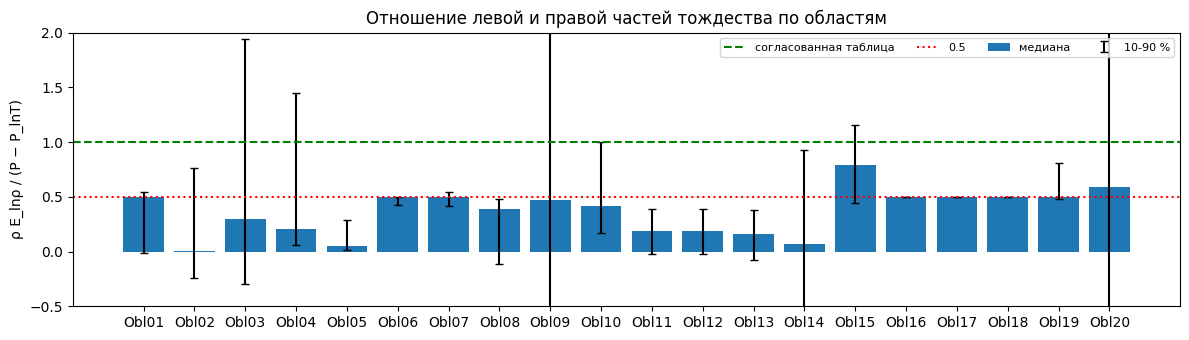

,ρ,T,ratio_p10,ratio_median,ratio_p90,|невязка| медиана,"dP/dρ<0, %","c_v<0, %","c_s²<0, %"
область,,,,,,,,,
Obl01,0.001..0.0971,0.1..95.7,-0.017,0.500,0.541,0.333,0.000,0.066,0.000
Obl02,0.001..0.0977,100..2.95e+03,-0.244,0.001,0.766,0.017,0.000,1.010,1.010
Obl03,0.001..0.0977,3e+03..2.97e+04,-0.294,0.299,1.939,0.000,0.000,0.000,0.000
Obl04,0.001..0.0983,3e+04..9.97e+04,0.059,0.210,1.447,0.000,0.000,0.000,0.000
Obl05,0.001..0.0977,1e+05..1e+07,0.012,0.051,0.288,0.001,0.000,0.000,0.000
Obl06,0.1..1.47,0.1..95.7,0.423,0.500,0.502,0.333,0.000,1.903,0.000
Obl07,0.1..1.48,100..2.96e+03,0.415,0.500,0.543,0.240,0.000,0.823,0.625
Obl08,0.1..1.48,3e+03..2.97e+04,-0.112,0.390,0.481,0.046,0.000,0.000,0.000
Obl09,0.1..1.49,3e+04..9.97e+04,-1.860,0.475,3.020,0.013,0.000,0.000,0.000


In [7]:
rows = []
for r in regions:
    lr, lt = np.log(r.rho), np.log(r.T)
    P_t, P_r = np.gradient(r.P, lt, lr)
    E_t, E_r = np.gradient(r.E, lt, lr)
    s = (slice(1, -1), slice(1, -1))
    lhs, rhs = (r.rho[None, :] * E_r)[s], (r.P - P_t)[s]
    good = np.abs(rhs) > 1e-3 * r.P[s]
    ratio = lhs[good] / rhs[good]
    d = fd_thermo_residual(r.rho, r.T, r.P, r.E)
    rows.append({"область": r.name, "ρ": f"{r.rho[0]:.3g}..{r.rho[-1]:.3g}", "T": f"{r.T[0]:.3g}..{r.T[-1]:.3g}",
                 "ratio_p10": np.percentile(ratio, 10), "ratio_median": np.median(ratio),
                 "ratio_p90": np.percentile(ratio, 90),
                 "|невязка| медиана": np.median(np.abs(d["thermo"][s])),
                 "dP/dρ<0, %": 100 * np.mean(d["P_r"][s] < 0), "c_v<0, %": 100 * np.mean(d["E_t"][s] < 0),
                 "c_s²<0, %": 100 * np.mean(d["cs2"][s] < 0)})
consistency = pd.DataFrame(rows).set_index("область")
consistency.to_csv(TAB / "data_consistency.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(consistency.index, consistency["ratio_median"], color="tab:blue", label="медиана")
ax.errorbar(consistency.index, consistency["ratio_median"],
            yerr=[consistency["ratio_median"] - consistency["ratio_p10"],
                  consistency["ratio_p90"] - consistency["ratio_median"]],
            fmt="none", ecolor="k", capsize=3, label="10-90 %")
ax.axhline(1.0, color="g", ls="--", label="согласованная таблица")
ax.axhline(0.5, color="r", ls=":", label="0.5")
ax.set_ylim(-0.5, 2.0); ax.set_ylabel("ρ E_lnρ / (P − P_lnT)"); ax.legend(fontsize=8, ncol=4)
ax.set_title("Отношение левой и правой частей тождества по областям")
fig.tight_layout(); fig.savefig(OUT / "consistency_ratio.png", dpi=120); plt.show()
consistency.style.format(precision=3)

### Устойчивость: где в данных $c_v < 0$

Ищем строки сетки (фиксированное $T$), где больше половины узлов имеют $c_v = (\partial E/\partial T)_\rho < 0$, и долю таких узлов в целом.

In [8]:
total = bad_total = 0
for r in regions:
    d = fd_thermo_residual(r.rho, r.T, r.P, r.E)
    bad = d["E_t"] < 0
    total += bad.size; bad_total += bad.sum()
    rows_bad = np.where(bad.mean(axis=1) > 0.5)[0]
    if len(rows_bad):
        print(f"{r.name}: строки T = {np.round(r.T[rows_bad], 3).tolist()[:8]} K "
              f"(всего {len(rows_bad)}), узлов c_v<0: {bad.mean():.2%}")
print(f"\nВсего узлов с c_v < 0 (конечные разности): {bad_total} из {total} ({bad_total / total:.2%})")

Obl02: строки T = [140.512, 142.922] K (всего 2), узлов c_v<0: 1.00%
Obl06: строки T = [0.119] K (всего 1), узлов c_v<0: 1.86%
Obl07: строки T = [141.49, 143.468] K (всего 2), узлов c_v<0: 0.82%
Obl12: строки T = [142.114, 143.734] K (всего 2), узлов c_v<0: 0.67%
Obl16: строки T = [0.177, 0.298, 0.326, 0.527, 0.747, 0.852] K (всего 6), узлов c_v<0: 8.72%
Obl17: строки T = [140.512, 142.922] K (всего 2), узлов c_v<0: 1.00%

Всего узлов с c_v < 0 (конечные разности): 4969 из 1130053 (0.44%)


### Шум

Для гладкой функции вторая разность $\Delta^2 \ln P$ вдоль сетки мала; для белого шума амплитуды $\sigma$ её стандартное отклонение равно $\sqrt{6}\,\sigma$.
Робастная оценка: $\sigma \approx 1.4826\cdot\mathrm{median}|\Delta^2 \ln P| / \sqrt 6$ (вдоль $\rho$ и вдоль $T$).

In [9]:
rows = []
for r in regions:
    lnP = np.log(r.P)
    est = lambda a: 1.4826 * np.median(np.abs(np.diff(lnP, 2, axis=a))) / np.sqrt(6)
    rows.append({"область": r.name, "σ(ln P) вдоль ρ, %": 100 * est(1), "σ(ln P) вдоль T, %": 100 * est(0),
                 "p99 |Δ² ln P| вдоль ρ, %": 100 * np.percentile(np.abs(np.diff(lnP, 2, axis=1)), 99)})
noise = pd.DataFrame(rows).set_index("область")
noise.T.style.format(precision=3)

область,Obl01,Obl02,Obl03,Obl04,Obl05,Obl06,Obl07,Obl08,Obl09,Obl10,Obl11,Obl12,Obl13,Obl14,Obl15,Obl16,Obl17,Obl18,Obl19,Obl20
"σ(ln P) вдоль ρ, %",0.011,0.001,0.000,0.000,0.000,0.001,0.004,0.002,0.001,0.002,0.003,0.002,0.001,0.000,0.001,0.000,0.000,0.000,0.000,0.004
"σ(ln P) вдоль T, %",0.000,0.001,0.000,0.001,0.000,0.000,0.002,0.001,0.001,0.002,0.000,0.000,0.001,0.000,0.003,0.000,0.000,0.000,0.000,0.006
"p99 |Δ² ln P| вдоль ρ, %",0.589,0.037,0.005,0.001,0.007,0.047,0.019,0.012,0.002,0.004,0.017,0.010,0.008,0.003,0.005,0.346,0.208,0.111,0.025,0.035


### Разрывы на границах областей

Соседние области не стыкуются в общих узлах (например, $\rho_{\max}$ = 0.0971 в Obl01 и $\rho_{\min}$ = 0.1 в Obl06), поэтому сравниваем крайнюю строку/столбец одной области
с интерполяцией крайней строки/столбца соседней и вычитаем ожидаемое изменение за счёт зазора (по локальной производной).
«Скачок» = $|\Delta \ln P|$ сверх ожидаемого.

In [10]:
def boundary_jump(lo, hi, axis):
    if axis == "T":
        x, xh = np.log(lo.rho), np.log(hi.rho)
        m = (x >= xh[0]) & (x <= xh[-1])
        a, b = np.log(lo.P[-1, m]), np.log(np.interp(x[m], xh, hi.P[0]))
        slope = (np.log(lo.P[-1, m]) - np.log(lo.P[-2, m])) / np.log(lo.T[-1] / lo.T[-2])
        gap = np.log(hi.T[0] / lo.T[-1]); where = lo.rho[m]
    else:
        x, xh = np.log(lo.T), np.log(hi.T)
        m = (x >= xh[0]) & (x <= xh[-1])
        a, b = np.log(lo.P[m, -1]), np.log(np.interp(x[m], xh, hi.P[:, 0]))
        slope = (np.log(lo.P[m, -1]) - np.log(lo.P[m, -2])) / np.log(lo.rho[-1] / lo.rho[-2])
        gap = np.log(hi.rho[0] / lo.rho[-1]); where = lo.T[m]
    excess = np.abs(b - a - slope * gap)
    k = int(np.argmax(excess))
    return np.median(excess), excess[k], where[k]

rows = []
for i in range(4):
    for j in range(5):
        k = 5 * i + j
        if j < 4:
            med, mx, at = boundary_jump(regions[k], regions[k + 1], "T")
            rows.append({"граница": f"{regions[k].name}|{regions[k+1].name}", "по": f"T ≈ {regions[k+1].T[0]:g} K",
                         "медиана, %": 100 * med, "максимум, %": 100 * mx, "где": f"ρ = {at:.3g}"})
        if i < 3:
            med, mx, at = boundary_jump(regions[k], regions[k + 5], "rho")
            rows.append({"граница": f"{regions[k].name}|{regions[k+5].name}", "по": f"ρ ≈ {regions[k+5].rho[0]:g}",
                         "медиана, %": 100 * med, "максимум, %": 100 * mx, "где": f"T = {at:.3g}"})
jumps = pd.DataFrame(rows).set_index("граница").sort_values("максимум, %", ascending=False)
jumps.to_csv(TAB / "boundary_jumps.csv", encoding="utf-8-sig")
jumps.head(10).style.format(precision=2)

,по,"медиана, %","максимум, %",где
граница,,,,
Obl02|Obl07,ρ ≈ 0.1,0.03,3.69,T = 143
Obl01|Obl02,T ≈ 100 K,0.01,0.06,ρ = 0.0685
Obl16|Obl17,T ≈ 100 K,0.04,0.05,ρ = 5.51
Obl01|Obl06,ρ ≈ 0.1,0.00,0.05,T = 95.7
Obl06|Obl07,T ≈ 100 K,0.01,0.04,ρ = 0.102
Obl07|Obl12,ρ ≈ 1.5,0.01,0.04,T = 143
Obl06|Obl11,ρ ≈ 1.5,0.03,0.04,T = 70.5
Obl17|Obl18,T ≈ 3000 K,0.03,0.04,ρ = 5.4
Obl19|Obl20,T ≈ 100000 K,0.02,0.03,ρ = 3.99e+03


На стыках областей скачки малы (≤0.06 % по $\ln P$). Исключение составляет стык Obl02|Obl07, но там максимум приходится на $T \approx 143$ K, т. е. на **внутренний скачок** в строке сетки, а не на границу.
Ищем в каждой области строку $T_j$ с наибольшим изломом $|\Delta_j \ln P - (\Delta_{j-1} + \Delta_{j+1})/2|$ (медиана по $\rho$).
В горячих областях найденный максимум отражает обычную кривизну (приращение положительное и плавное), а аномалиями считаются отрицательные приращения и изломы в несколько процентов.

In [11]:
rows = []
for r in regions:
    d = np.diff(np.log(r.P), axis=0)
    kink = np.median(np.abs(d[1:-1] - 0.5 * (d[:-2] + d[2:])), axis=1)
    j = int(np.argmax(kink)) + 1
    step = np.exp(d[j]) - 1
    rows.append({"область": r.name, "T_j → T_j+1, K": f"{r.T[j]:.1f} → {r.T[j+1]:.1f}",
                 "излом (медиана), %": 100 * kink[j - 1],
                 "приращение P на шаге (медиана), %": 100 * np.median(step),
                 "max |приращение P|, %": 100 * np.abs(step).max()})
steps = pd.DataFrame(rows).set_index("область")
steps.style.format(precision=2)

,"T_j → T_j+1, K","излом (медиана), %","приращение P на шаге (медиана), %","max |приращение P|, %"
область,,,,
Obl01,70.5 → 73.6,4.10,4.19,4.46
Obl02,140.5 → 142.9,35.33,-28.33,29.26
Obl03,3034.7 → 3069.9,0.00,1.16,1.16
Obl04,78795.6 → 79051.1,0.00,0.32,0.33
Obl05,296730.2 → 303677.1,0.00,2.36,2.51
Obl06,70.5 → 73.6,0.13,0.15,1.08
Obl07,141.5 → 143.5,1.96,-1.85,11.42
Obl08,3326.7 → 3358.2,0.00,0.59,0.89
Obl09,78795.6 → 79051.1,0.00,0.34,0.36


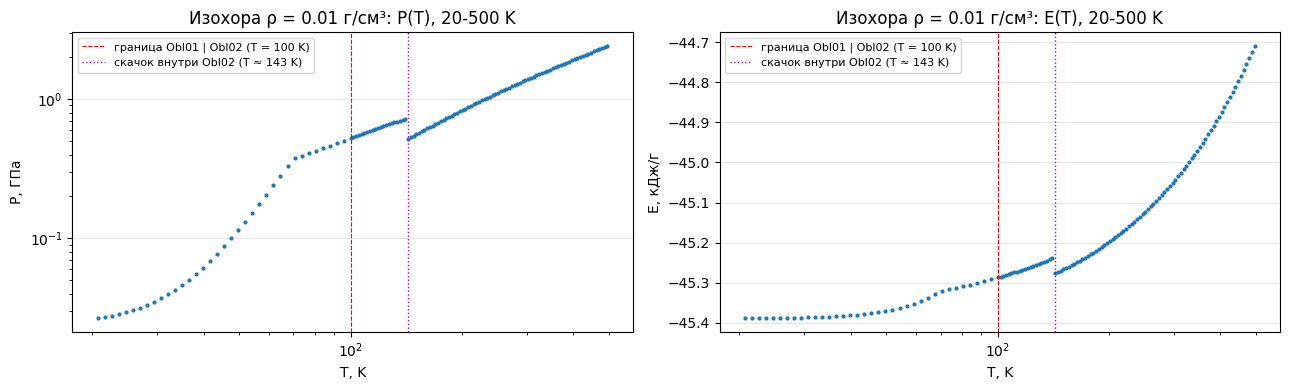

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, field in zip(axes, ("P", "E")):
    x, y = eda.section_T(regions, 0.01, field)
    m = (x > 20) & (x < 500)
    ax.plot(x[m], y[m], ".", ms=4)
    ax.axvline(100, color="r", ls="--", lw=0.8, label="граница Obl01 | Obl02 (T = 100 K)")
    ax.axvline(143, color="m", ls=":", lw=1.0, label="скачок внутри Obl02 (T ≈ 143 K)")
    ax.set_xscale("log"); ax.set_yscale("log" if field == "P" else "linear")
    ax.set_xlabel("T, K"); ax.set_ylabel("P, ГПа" if field == "P" else "E, кДж/г")
    ax.set_title(f"Изохора ρ = 0.01 г/см³: {field}(T), 20-500 K"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "boundary_jump_rho001.png", dpi=120); plt.show()

## 1.3. Бейзлайн: билинейная интерполяция

`eos.baseline.BilinearEOS`: в каждой из 20 областей используется `scipy.interpolate.RegularGridInterpolator` (линейный) в «родных» осях области
($\log_{10}$ для логарифмической оси, линейно для линейной). Область для запроса определяется по границам `RHO_EDGES`, `T_EDGES`.

Таблица строится по узлам с чётными индексами, а оценивается в test-узлах (нечётные индексы), то есть ровно в центрах её ячеек, т. е. в худших для интерполяции точках.
Ошибки: $|P_\text{pred} - P|/|P|$ и $|E_\text{pred} - E|/(|E| + 1\,\text{кДж/г})$ (у $E$ есть нули, поэтому знаменатель с «полом»).

In [13]:
te = ds["split"] == 2
t0 = time.perf_counter()
P_b, E_b = bl.predict(ds["rho"][te], ds["T"][te])
t_test = time.perf_counter() - t0
metrics = summarize(P_b, E_b, ds["P"][te], ds["E"][te])
metrics["size_MB"] = bl.size_mb()
metrics["time_1e5_s"] = benchmark(bl.predict, n=100_000, repeats=3)
print(f"test: {te.sum():,} точек, предсказание за {t_test:.2f} с".replace(",", " "))
print(f"10^5 случайных запросов: {metrics['time_1e5_s']:.3f} с ({1e6 * metrics['time_1e5_s'] / 1e5:.2f} мкс/запрос)")
print(f"Объём таблиц (float64): {metrics['size_MB']:.2f} МБ")

with open(REPORT_DIR / "baseline_metrics.json", encoding="utf-8") as f:
    saved = json.load(f)
tab = pd.DataFrame({"P": [metrics[f"P_{q}_%"] for q in ("mean", "median", "p95", "p99", "max")],
                    "E": [metrics[f"E_{q}_%"] for q in ("mean", "median", "p95", "p99", "max")]},
                   index=["mean, %", "median, %", "p95, %", "p99, %", "max, %"])
print("Сохранённые метрики (artifacts/reports/baseline_metrics.json):")
print(pd.DataFrame(saved).T.drop(columns="note", errors="ignore").to_string(float_format=lambda v: f"{v:.4g}"))
tab.style.format("{:.4f}")

test: 281 846 точек  предсказание за 0.12 с
10^5 случайных запросов: 0.073 с (0.73 мкс/запрос)
Объём таблиц (float64): 4.36 МБ
Сохранённые метрики (artifacts/reports/baseline_metrics.json):
                P_mean_% P_median_% P_p95_% P_p99_% P_max_% E_mean_% E_median_% E_p95_% E_p99_% E_max_% size_MB time_1e5_s
bilinear_coarse   0.0554   0.007766  0.2025  0.3257   21.95  0.02471    0.01331 0.08037   0.175    7.26   4.357    0.06197
bilinear_full        NaN        NaN     NaN     NaN     NaN      NaN        NaN     NaN     NaN     NaN   17.31    0.06217


,P,E
"mean, %",0.0554,0.0247
"median, %",0.0078,0.0133
"p95, %",0.2025,0.0804
"p99, %",0.3257,0.1750
"max, %",21.9455,7.2604


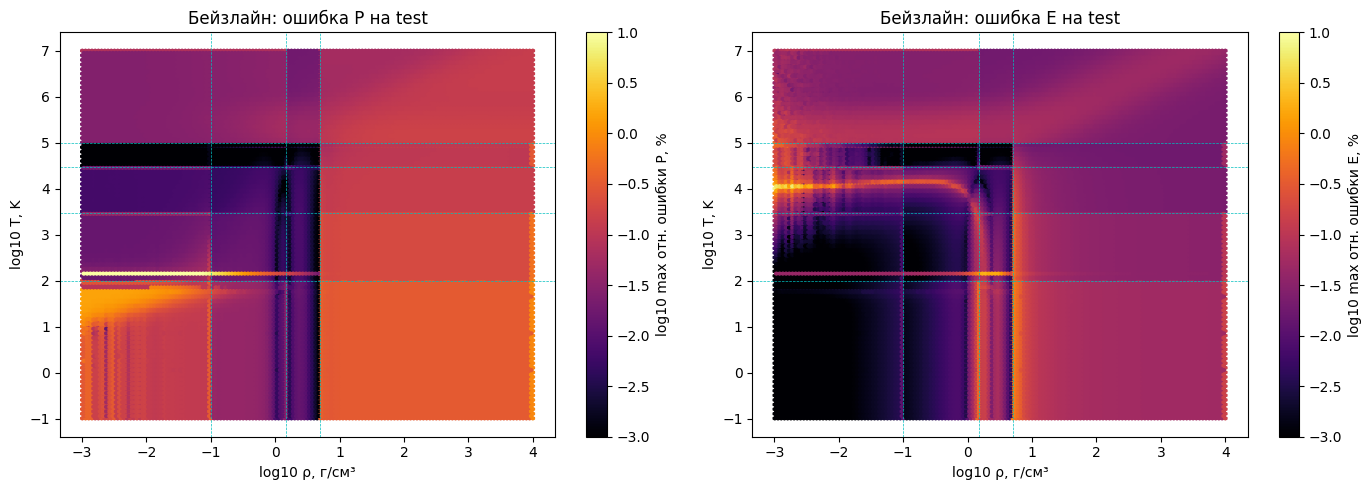

,"P mean, %","P p99, %","P max, %","E mean, %","E max, %"
Obl01,0.279,1.511,1.530,0.001,0.013
Obl02,0.206,0.204,21.946,0.003,0.106
Obl03,0.007,0.011,0.022,0.080,7.260
Obl04,0.000,0.001,0.002,0.026,0.503
Obl05,0.028,0.034,0.091,0.045,0.337
Obl06,0.035,0.117,0.278,0.017,0.503
Obl07,0.025,0.018,5.898,0.007,0.720
Obl08,0.006,0.010,0.011,0.023,0.316
Obl09,0.001,0.002,0.011,0.001,0.029
Obl10,0.036,0.060,0.099,0.047,0.091


In [14]:
eP, eE = rel_errors(P_b, E_b, ds["P"][te], ds["E"][te])
reg = ds["region"][te]
per_region = pd.DataFrame({
    "P mean, %": [100 * eP[reg == k].mean() for k in range(20)],
    "P p99, %": [100 * np.percentile(eP[reg == k], 99) for k in range(20)],
    "P max, %": [100 * eP[reg == k].max() for k in range(20)],
    "E mean, %": [100 * eE[reg == k].mean() for k in range(20)],
    "E max, %": [100 * eE[reg == k].max() for k in range(20)]}, index=[r.name for r in regions])
per_region.to_csv(TAB / "baseline_per_region.csv", encoding="utf-8-sig")

lr, lt = np.log10(ds["rho"][te]), np.log10(ds["T"][te])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, e, name in zip(axes, (eP, eE), ("P", "E")):
    hb = ax.hexbin(lr, lt, C=np.log10(100 * e + 1e-6), reduce_C_function=np.max, gridsize=140,
                   cmap="inferno", vmin=-3, vmax=1)
    fig.colorbar(hb, ax=ax, label=f"log10 max отн. ошибки {name}, %")
    for x in np.log10(RHO_EDGES[1:-1]): ax.axvline(x, color="c", lw=0.5, ls="--")
    for y in np.log10(T_EDGES[1:-1]): ax.axhline(y, color="c", lw=0.5, ls="--")
    ax.set_xlabel("log10 ρ, г/см³"); ax.set_ylabel("log10 T, K"); ax.set_title(f"Бейзлайн: ошибка {name} на test")
fig.tight_layout(); fig.savefig(OUT / "baseline_error_map.png", dpi=120); plt.show()
per_region.style.format(precision=3)

## 1.4. Коэффициенты нормировки

Сохранены в `artifacts/models/normalization.json` (подбираются по train, используются и при обучении, и в обёртке инференса):

* входы: $x = 2(\log_{10} q - lo)/(hi - lo) - 1 \in [-1, 1]$, $q \in \{\rho, T\}$, данные равномерны по логарифмам;
* выходы: $y = (\operatorname{asinh}((q - q_0)/s) - \mu)/\sigma$; при $|q| \gg s$ asinh ведёт себя как логарифм (относительная точность на 12 порядках $P$),
  около нуля он линеен, поэтому знакопеременная $E$ допустима. $P$: $q_0 = 0$, $s = 10^{-5}$ ГПа; $E$: $q_0 = -50$ кДж/г (ниже минимума −46.8), $s = 1$ кДж/г.

Ниже проверка обратимости и распределения нормированных величин.

{
  "log_rho_lo": -3.0,
  "log_rho_hi": 4.0,
  "log_T_lo": -1.0,
  "log_T_hi": 7.0,
  "P_scale": 1e-05,
  "E_offset": -50.0,
  "E_scale": 1.0,
  "yP_mu": 19.44850928647844,
  "yP_sigma": 4.534613992430756,
  "yE_mu": 6.296383403559437,
  "yE_sigma": 2.4131914748763914,
  "description": {
    "inputs": "x = 2*(log10(q) - lo)/(hi - lo) - 1, q in {rho [g/cm^3], T [K]}",
    "outputs": "y = (asinh((q - offset)/scale) - mu)/sigma, q in {P [GPa], E [kJ/g]}, offset = 0 for P and E_offset for E"
  }
}
x: [[-1. -1.], [1. 1.]]
y на train: mean [-0.  0.], std [1. 1.]
Обратное преобразование: max отн. ошибка P 5.6e-15, max |ΔE| 4.4e-10 кДж/г


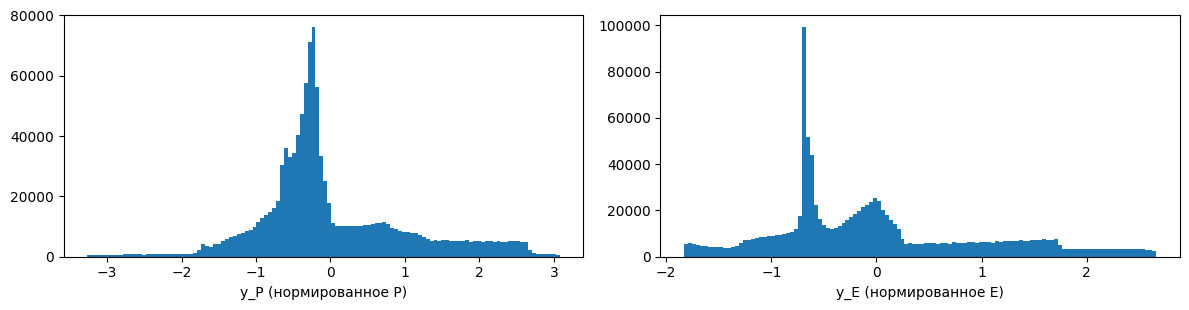

In [15]:
with open(NORM_FILE, encoding="utf-8") as f:
    print(json.dumps(json.load(f), indent=2, ensure_ascii=False))
norm = Normalizer.load()
X = norm.x(ds["rho"], ds["T"])
Y = norm.y(P, E)
P_back = norm.P_scale * np.sinh(Y[:, 0] * norm.yP_sigma + norm.yP_mu)
E_back = norm.E_offset + norm.E_scale * np.sinh(Y[:, 1] * norm.yE_sigma + norm.yE_mu)
print(f"x: [{X.min(0).round(3)}, {X.max(0).round(3)}]")
tr = split == 0
print(f"y на train: mean {Y[tr].mean(0).round(4)}, std {Y[tr].std(0).round(4)}")
print(f"Обратное преобразование: max отн. ошибка P {np.max(np.abs(P_back / P - 1)):.1e}, "
      f"max |ΔE| {np.max(np.abs(E_back - E)):.1e} кДж/г")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(Y[:, 0], bins=120); axes[0].set_xlabel("y_P (нормированное P)")
axes[1].hist(Y[:, 1], bins=120); axes[1].set_xlabel("y_E (нормированное E)")
fig.tight_layout(); fig.savefig(OUT / "normalized_targets.png", dpi=120); plt.show()

## Выводы по модулю 1 и план

**Данные.** 1 130 000 узлов в 20 прямоугольных областях; NaN нет. $P > 0$ везде, $5\cdot10^{-4}$ … $1.6\cdot10^{9}$ ГПа (12 порядков);
$E$ от −46.8 до $1.68\cdot10^5$ кДж/г и меняет знак. Отсюда логарифмические входы и asinh-нормировка выходов.

**Физика данных.**
* В холодных и плотных областях (Obl01, Obl06, Obl07, Obl16-19) отношение $\rho E_{\ln\rho}/(P - P_{\ln T}) \approx 0.5$: таблица систематически несогласована в 2 раза. В горячих областях ближе к 1. Поэтому термодинамическая согласованность в PINN задаётся **мягким штрафом с настраиваемым весом**, а не жёсткое ограничение (жёсткое противоречило бы данным).
* Данные в основном гладкие (робастная оценка шума $\ln P$ ≲ 0.01 %), но в холодных областях Obl01 и Obl16-18 есть локальная «рябь» до 0.2-0.6 % (p99 $|\Delta^2 \ln P|$). Именно там у бейзлайна наибольшая средняя ошибка.
* **Ступенька в строке $T \approx 141$-$143$ K**: $P$ скачком падает на ~28 % при $\rho < 0.1$ (Obl02), до 11 % при $\rho$ = 0.1-1.5 (Obl07) и ≲0.3 % в плотных областях; в этих строках $c_v < 0$ во всех четырёх диапазонах плотности (Obl02, 07, 12, 17). Ещё один излом есть при $T \approx 70$ K (Obl01, +4 %). Ещё $c_v < 0$ встречается при $T < 1$ K (Obl06, Obl16), где $E$ почти не зависит от $T$. Всего $c_v<0$ в 0.44 % узлов; $\partial P/\partial\rho < 0$ нет нигде.
* На самих стыках областей скачки малы (≤0.06 % по $\ln P$), но сетки соседних областей не совпадают (зазоры вида 0.0971 → 0.1 г/см³).
  Гладкая сеть сгладит ступеньку при 143 K, поэтому ошибка там будет выше, чем в среднем; при этом физика (знак $c_v$) там будет правильнее, чем у таблицы.

**Бейзлайн.** Средняя ошибка $P$ 0.055 % (p99 0.33 %), $E$ 0.025 % (p99 0.18 %); 4.4 МБ таблиц, $10^5$ запросов ≈ 0.1 с. Это планка точности для нейросети;
у интерполяции нет гладких производных (они разрывны на рёбрах ячеек) и никакой гарантии физики, их и даёт PINN. Максимальные ошибки бейзлайна (22 % по $P$, 7 % по $E$) приходятся на ступеньку при 143 K и на резкий рост $E$ около $T \approx 10^4$ K.

**Далее.** Vanilla MLP (SiLU, 4×128, встроенная нормировка) → производные через autograd → PINN-loss
(данные + $w_\text{thermo}\cdot$невязка² + штрафы $\partial P/\partial\rho>0$, $c_v>0$, $0<c_s<c$, warmup 20 % только по данным) → TorchScript + обёртка
`EOSSurrogate` (`predict`, `sound_speed`, `check_physics`, `derivatives`) → сжатие (fp16, int8, frozen TorchScript). Подробности: `docs/README_Module1.md`.